<a href="https://colab.research.google.com/github/KoolBoi666/3-HP-rut-FBA-analysis/blob/main/3HP_rut_FBA_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install cobra -q

In [2]:
import os, itertools, platform, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cobra
from cobra.io import load_model
from cobra.flux_analysis import flux_variability_analysis as fva, pfba

os.makedirs('results', exist_ok=True)
FLOOR = 0.10                              # minimum growth as a fraction of the maximum
BM = 'BIOMASS_Ec_iML1515_core_75p37M'     # iML1515 biomass reaction

In [3]:
# 1. Core-model check with succinate (Section 3.1)
core = load_model('textbook')
CB = 'Biomass_Ecoli_core'
g_core = core.slim_optimize()

def core_max(*genes):
    # max succinate secretion with the given genes deleted, growth >= FLOOR * max
    with core:
        for g in genes:
            g.knock_out()
        core.reactions.get_by_id(CB).lower_bound = FLOOR * g_core
        core.objective = 'EX_succ_e'
        return core.slim_optimize()

base_core = core_max()
single = np.array([core_max(g) for g in core.genes])
double = np.array([core_max(a, b) for a, b in itertools.combinations(core.genes, 2)])
print(f'growth {g_core:.4f} | succinate baseline {base_core:.4f}')
for name, v in [('single', single), ('double', double)]:
    ok = v[~np.isnan(v)]
    print(f'{name}: {len(ok)} of {len(v)} feasible, above baseline: {(ok > base_core + 1e-4).sum()}')

def min_flux():
    # minimum succinate flux at maximum growth (above 0 means growth-coupled)
    return fva(core, ['EX_succ_e'], fraction_of_optimum=1.0).loc['EX_succ_e', 'minimum']

coupled = 0
for g in core.genes:
    with core:
        g.knock_out()
        if core.slim_optimize() > 1e-6:   # skip lethal knockouts
            coupled += min_flux() > 1e-6
print('wild-type minimum flux:', min_flux(), '| growth-coupled knockouts:', coupled)

growth 0.8739 | succinate baseline 14.7849
single: 130 of 137 feasible, above baseline: 0
double: 8332 of 9316 feasible, above baseline: 0
wild-type minimum flux: 0.0 | growth-coupled knockouts: 0


In [4]:
# 2. iML1515 baseline (Sections 2.1 and 3.2)
url = 'https://bigg.ucsd.edu/static/models/iML1515.xml.gz'
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
open('iML1515.xml.gz', 'wb').write(urllib.request.urlopen(req).read())
m = cobra.io.read_sbml_model('iML1515.xml.gz')
print(len(m.reactions), 'reactions,', len(m.metabolites), 'metabolites,', len(m.genes), 'genes')
print('limited uptake:', {k: v for k, v in m.medium.items() if v != 1000}, '| ATPM:', m.reactions.ATPM.lower_bound)

g0 = m.slim_optimize()                    # maximum growth rate

def best(floor=FLOOR, product='EX_3hpp_e'):
    # max product secretion with growth >= floor * g0 (model is restored afterwards)
    with m:
        m.reactions.get_by_id(BM).lower_bound = floor * g0
        m.objective = product
        return m.slim_optimize()

base = best()
print(f'growth {g0:.4f} | max 3-HP at {FLOOR:.0%} floor: {base:.4f}')

2712 reactions, 1877 metabolites, 1516 genes
limited uptake: {'EX_glc__D_e': 10.0} | ATPM: 6.86
growth 0.8770 | max 3-HP at 10% floor: 10.5724


In [5]:
# 3. Route tracing on the plain FBA and pFBA solutions (Sections 2.4 and 3.3)
SKIP = {'h_c', 'h_p', 'h_e', 'h2o_c', 'h2o_p', 'h2o_e', 'atp_c', 'adp_c', 'amp_c', 'nad_c', 'nadh_c',
        'nadp_c', 'nadph_c', 'pi_c', 'ppi_c', 'co2_c', 'nh4_c', 'coa_c', 'o2_c', 'fad_c', 'fadh2_c',
        'q8_c', 'q8h2_c'}

def trace(met_id, sol, tol, seen=None, d=0):
    # print the reactions producing a metabolite, then repeat for their substrates
    seen = set() if seen is None else seen
    if met_id in seen:
        return
    seen.add(met_id)
    met = m.metabolites.get_by_id(met_id)
    for r in met.reactions:
        v = sol.fluxes[r.id]
        if abs(v) < tol or r.metabolites[met] * v <= 0:
            continue
        print('  ' * d + f'{met_id} <- {r.id} ({v:.3f}) genes={[g.id for g in r.genes]}')
        for s, c in r.metabolites.items():
            if c * v < 0 and s.id not in SKIP:
                trace(s.id, sol, tol, seen, d + 1)

with m:
    m.reactions.get_by_id(BM).lower_bound = FLOOR * g0
    m.objective = 'EX_3hpp_e'
    plain = m.optimize()
    pf = pfba(m)                          # same product flux, smallest total flux

tol = 0.05 * base                         # ignore reactions below 5% of the product flux
print('--- plain FBA'); trace('3hpp_c', plain, tol)
print('--- pFBA');      trace('3hpp_c', pf, tol)
print('SUCDi flux: plain', round(plain.fluxes['SUCDi'], 1), '| pFBA', round(pf.fluxes['SUCDi'], 1))
for rid in ['MSAR', '3HPPtpp', '3HPPtex']:
    print(rid, '| gene rule:', m.reactions.get_by_id(rid).gene_reaction_rule or 'none')

--- plain FBA
3hpp_c <- MSAR (10.572) genes=['b1008', 'b1539']
  msa_c <- 3AMACHYD (10.572) genes=['b1009']
    3amac_c <- POAACR (10.572) genes=['b1010']
      poaac_c <- URACPAH (10.572) genes=['b1011']
        uracp_c <- PYROX (10.572) genes=['b1012', 'b1007']
          ura_c <- PYNP2r (10.572) genes=['b3831']
            uri_c <- NTD2 (10.572) genes=['b4374', 'b0675', 'b2744']
              ump_c <- OMPDC (10.601) genes=['b1281']
                orot5p_c <- ORPT (-10.601) genes=['b3642']
                  orot_c <- DHORDfum (10.601) genes=[]
                    dhor__S_c <- DHORTS (-10.601) genes=['b1062']
                      cbasp_c <- ASPCT (10.601) genes=['b4245', 'b4244']
                        asp__L_c <- ASPTA (-10.829) genes=['b0928', 'b4054']
                          glu__L_c <- GLUDy (-11.322) genes=['b3212', 'b1761', 'b3213']
                            akg_c <- ICDHyr (5.376) genes=['b1136']
                              icit_c <- ACONTb (5.376) genes=['b1276', 'b011

In [6]:
# 4. Necessity controls (Section 3.4)
def deleted(rxns=(), genes=()):
    with m:
        for r in rxns:
            m.reactions.get_by_id(r).knock_out()
        for g in genes:
            m.genes.get_by_id(g).knock_out()
        return best()

tests = {'no deletion': ([], []), 'MSAR': (['MSAR'], []), 'rutD (b1009)': ([], ['b1009']),
         'rutC (b1010)': ([], ['b1010']), 'DHORDfum': (['DHORDfum'], []), 'R1PK': (['R1PK'], []),
         'DHORDfum + R1PK': (['DHORDfum', 'R1PK'], []), '3HPPtpp': (['3HPPtpp'], []), '3HPPtex': (['3HPPtex'], [])}
for name, (rx, gn) in tests.items():
    print(f'{name:16s} {deleted(rx, gn):.4f}')

no deletion      10.5724
MSAR             0.0000
rutD (b1009)     0.0000
rutC (b1010)     0.0000
DHORDfum         10.5724
R1PK             10.5724
DHORDfum + R1PK  10.5724
3HPPtpp          0.0000
3HPPtex          0.0000


In [7]:
# 5. Single-gene knockout screen (Section 3.5)
rows = []
for g in m.genes:
    with m:
        g.knock_out()
        rows.append((g.id, g.name, best()))
ko = pd.DataFrame(rows, columns=['gene', 'name', 'flux']).dropna().sort_values('flux', ascending=False)
ko.to_csv('results/single_knockouts.csv', index=False)

d = ko.flux - base
print(f'{len(ko)} of {len(m.genes)} feasible | within 0.001: {(d.abs() <= 1e-3).sum()} | higher: {(d > 1e-3).sum()} | lower: {(d < -1e-3).sum()}')
print('largest increase:', round(d.max(), 4)); print(ko.head(8).to_string(index=False))
print('lowest 30:'); print(ko.tail(30).iloc[::-1].to_string(index=False))

1333 of 1516 feasible | within 0.001: 1263 | higher: 0 | lower: 70
largest increase: 0.0004
 gene name      flux
b0154 hemL 10.572719
b3843 ubiD 10.572626
b3187 ispB 10.572626
b4040 ubiA 10.572626
b3368 cysG 10.572547
b3997 hemE 10.572523
b3850 hemG 10.572523
b0417 thiL 10.572491
lowest 30:
 gene name         flux
b1010 rutC 0.000000e+00
b1009 rutD 0.000000e+00
b1012 rutA 0.000000e+00
b1007 rutF 6.415370e-16
b1011 rutB 2.561831e-15
b3732 atpD 4.587963e+00
b3736 atpF 4.587963e+00
b3733 atpG 4.587963e+00
b3735 atpH 4.587963e+00
b3738 atpB 4.587963e+00
b3734 atpA 4.587963e+00
b3731 atpC 4.587963e+00
b3737 atpE 4.587963e+00
b1779 gapA 9.107773e+00
b2926  pgk 9.107773e+00
b2779  eno 9.368103e+00
b0521 ybcF 9.612776e+00
b0429 cyoD 9.710222e+00
b0432 cyoA 9.710222e+00
b0430 cyoC 9.710222e+00
b0431 cyoB 9.710222e+00
b3956  ppc 9.911267e+00
b2285 nuoE 1.006836e+01
b2280 nuoJ 1.006836e+01
b2276 nuoN 1.006836e+01
b2283 nuoG 1.006836e+01
b2279 nuoK 1.006836e+01
b2287 nuoB 1.006836e+01
b2282 nuoH 1

 floor  growth    flux
  0.00  0.0000 11.7439
  0.05  0.0438 11.1581
  0.10  0.0877 10.5724
  0.20  0.1754  9.4008
  0.30  0.2631  8.2292
  0.50  0.4385  5.8861
  0.70  0.6139  3.5414
  0.90  0.7893  1.1805
  1.00  0.8770  0.0000
slope -13.385 | intercept 11.748 | R2 1.00000
segment slopes: [-13.36 -13.36 -13.36 -13.36 -13.36 -13.37 -13.46 -13.46]


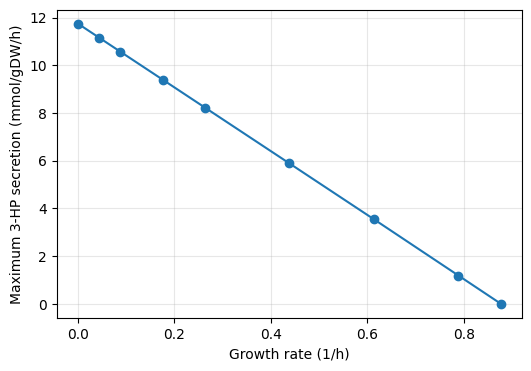

In [8]:
# 6. Production envelope (Sections 2.5 and 3.6)
fl = [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0]
env = pd.DataFrame({'floor': fl, 'growth': [f * g0 for f in fl], 'flux': [best(f) for f in fl]})
env.to_csv('results/production_envelope.csv', index=False)
slope, icpt = np.polyfit(env.growth, env.flux, 1)
r2 = np.corrcoef(env.growth, env.flux)[0, 1] ** 2
print(env.round(4).to_string(index=False))
print(f'slope {slope:.3f} | intercept {icpt:.3f} | R2 {r2:.5f}')
print('segment slopes:', np.round(np.diff(env.flux) / np.diff(env.growth), 2))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(env.growth, env.flux, 'o-')
ax.set(xlabel='Growth rate (1/h)', ylabel='Maximum 3-HP secretion (mmol/gDW/h)')
ax.grid(alpha=0.3)
fig.savefig('results/production_envelope.png', dpi=300, bbox_inches='tight')

In [9]:
# 7. Doubling glucose uptake at zero growth, with and without ATP maintenance (Section 3.7)
def doubling(atpm=None):
    with m:
        if atpm is not None:
            m.reactions.ATPM.lower_bound = atpm
        glc = m.reactions.get_by_id('EX_glc__D_e')
        a = best(0)
        glc.lower_bound *= 2
        return a, best(0), -glc.lower_bound / 2

for label, atpm in [('ATPM as in model', None), ('ATPM = 0', 0)]:
    a, b, uptake = doubling(atpm)
    print(f'{label}: {a:.4f} -> {b:.4f} (x{b / a:.4f}) | yield {a / uptake:.2f} mol/mol glucose')

ATPM as in model: 11.7439 -> 23.8283 (x2.0290) | yield 1.17 mol/mol glucose
ATPM = 0: 12.0844 -> 24.1687 (x2.0000) | yield 1.21 mol/mol glucose


In [10]:
# 8. Pyrimidine demand of the biomass reaction versus the 3-HP flux (Section 3.8)
bm = m.reactions.get_by_id(BM)
dem = {x: -bm.metabolites[m.metabolites.get_by_id(x)] * g0 for x in ['utp_c', 'ctp_c', 'dttp_c', 'dctp_c']}
tot = sum(dem.values())
print({k: round(v, 3) for k, v in dem.items()}, '| total at max growth:', round(tot, 3))
print(f'3-HP flux / demand at the floor: {base / (FLOOR * tot):.0f}')
print('OMP decarboxylase flux (pFBA):', round(pf.fluxes['OMPDC'], 3), '| 3-HP flux + demand at the floor:', round(base + FLOOR * tot, 3))

{'utp_c': 0.126, 'ctp_c': 0.117, 'dttp_c': 0.023, 'dctp_c': 0.024} | total at max growth: 0.29
3-HP flux / demand at the floor: 364
OMP decarboxylase flux (pFBA): 10.601 | 3-HP flux + demand at the floor: 10.601


In [11]:
# 9. Record versions
from importlib.metadata import version
with open('results/environment.txt', 'w') as f:
    f.write(f'python {platform.python_version()}\n')
    f.write(''.join(f'{p} {version(p)}\n' for p in ['cobra', 'optlang', 'numpy', 'pandas', 'matplotlib']))
    f.write(f'solver {m.solver.interface.__name__}\n')
print(open('results/environment.txt').read())

python 3.13.16
cobra 0.32.1
optlang 1.9.1
numpy 2.1.3
pandas 2.2.3
matplotlib 3.10.0
solver optlang.glpk_interface

